# RSNA Pneumonia Detection Challenge — Data Download and Preview

This notebook downloads and explores the **RSNA Pneumonia Detection Challenge** dataset for later zero-shot evaluation with UniMed-CLIP.

## Before running
1. Create/sign in to a Kaggle account.
2. Open the RSNA Pneumonia Detection Challenge on Kaggle and accept the competition rules if Kaggle asks you to do so.
3. Make sure you have enough free disk space. The Kaggle competition download is about 4 GB compressed, and extraction requires additional space.
4. In VS Code, select a Python/Jupyter kernel for this notebook.

The notebook will create a local `data/rsna_pneumonia/` directory next to the notebook.

## 1. Install required packages

Run this cell once. If VS Code asks you to restart the kernel afterward, restart it before continuing.

In [1]:
%pip install -q kaggle pandas numpy matplotlib pydicom


You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


## 2. Set up Kaggle authentication

The current Kaggle CLI supports browser-based OAuth login. The easiest approach in VS Code is to open the integrated **Terminal** and run:

```bash
kaggle auth login
```

A browser window should open so you can authorize Kaggle. After that, return here and run the next cell.

If you already configured Kaggle authentication previously, you can skip the login step.

In [2]:
import subprocess

result = subprocess.run(
    ["kaggle", "--version"],
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout else result.stderr)


Kaggle API 1.7.4.5



## 3. Define the download folder


In [3]:
from pathlib import Path

DATA_DIR = Path("data/rsna_pneumonia")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset folder:", DATA_DIR.resolve())


Dataset folder: /Users/pc123/Documents/Repos/CLIP Project/Data Analysis/data/rsna_pneumonia


## 4. Download the RSNA training labels and class info

In [7]:
import subprocess

competition = "rsna-pneumonia-detection-challenge"

files = [
    "stage_2_train_labels.csv",
    "stage_2_detailed_class_info.csv"
]

for file_name in files:
    command = [
        "kaggle",
        "competitions",
        "download",
        competition,
        "--file",
        file_name,
        "--path",
        str(DATA_DIR)
    ]

    print("Downloading:", file_name)
    subprocess.run(command, check=True)

print("Done.")

Downloading: stage_2_train_labels.csv


/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



Downloading: stage_2_detailed_class_info.csv


100%|██████████| 664k/664k [00:00<00:00, 748MB/s]
/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



Done.


100%|██████████| 581k/581k [00:00<00:00, 822MB/s]


## 5. Extract any nested ZIP files

Depending on how Kaggle packages the competition files, image folders may already be extracted. This cell safely extracts any ZIP archives that remain.

In [16]:
import subprocess
import zipfile
from pathlib import Path

competition = "rsna-pneumonia-detection-challenge"

files = [
    "stage_2_train_labels.csv",
    "stage_2_detailed_class_info.csv"
]

for file_name in files:
    file_path = DATA_DIR / file_name

    # Download
    command = [
        "kaggle",
        "competitions",
        "download",
        competition,
        "--file",
        file_name,
        "--path",
        str(DATA_DIR)
    ]

    print("Downloading:", file_name)
    subprocess.run(command, check=True)

    # Kaggle may save a ZIP archive with a .csv filename
    if zipfile.is_zipfile(file_path):
        print("Compressed file detected. Extracting:", file_name)

        zip_path = DATA_DIR / f"{file_name}.zip"

        # Rename the compressed download
        if not zip_path.exists():
            file_path.rename(zip_path)

        # Extract the real CSV
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(DATA_DIR)

        print("Extracted:", file_name)

print("\nDownload and extraction complete.")

Downloading: stage_2_train_labels.csv


/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



Compressed file detected. Extracting: stage_2_train_labels.csv
Extracted: stage_2_train_labels.csv
Downloading: stage_2_detailed_class_info.csv


100%|██████████| 664k/664k [00:00<00:00, 1.00GB/s]
/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



Compressed file detected. Extracting: stage_2_detailed_class_info.csv
Extracted: stage_2_detailed_class_info.csv

Download and extraction complete.


100%|██████████| 581k/581k [00:00<00:00, 729MB/s]


## 6. Inspect the downloaded files


In [17]:
for path in sorted(DATA_DIR.iterdir()):
    if path.is_dir():
        count = sum(1 for _ in path.iterdir())
        print(f"[DIR]  {path.name:<35} {count:,} items")
    else:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"[FILE] {path.name:<35} {size_mb:,.2f} MB")


[FILE] stage_2_detailed_class_info.csv     1.57 MB
[FILE] stage_2_detailed_class_info.csv.zip 0.57 MB
[FILE] stage_2_train_labels.csv            1.42 MB
[FILE] stage_2_train_labels.csv.zip        0.65 MB


## 7. Load the annotation tables

`stage_2_train_labels.csv` contains the pneumonia target and bounding boxes. A positive image can appear more than once because one image can contain multiple bounding boxes.

`stage_2_detailed_class_info.csv` gives the broader class: **Normal**, **No Lung Opacity / Not Normal**, or **Lung Opacity**.

In [24]:
import pandas as pd

labels_path = DATA_DIR / "stage_2_train_labels.csv"
class_info_path = DATA_DIR / "stage_2_detailed_class_info.csv"

labels = pd.read_csv(labels_path)
class_info = pd.read_csv(class_info_path)

print("Labels shape:", labels.shape)
print("Class-info shape:", class_info.shape)

print()
print("Labels")
display(labels.head())

print()
print("Class Info")
display(class_info.head())


Labels shape: (30227, 6)
Class-info shape: (30227, 2)

Labels


,patientId,x,y,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1



Class Info


,patientId,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,No Lung Opacity / Not Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,No Lung Opacity / Not Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,Lung Opacity


## 8. Look at the three diagnostic groups

Because pneumonia images may have multiple bounding boxes, class counts should be calculated using one row per patient/image.

In [19]:
class_per_patient = class_info.drop_duplicates(subset="patientId")

class_counts = class_per_patient["class"].value_counts()
display(class_counts.to_frame("number_of_images"))


,number_of_images
class,
No Lung Opacity / Not Normal,11821
Normal,8851
Lung Opacity,6012


# 9. Download and extract the RSNA training images

In [ ]:
import subprocess
from pathlib import Path

competition = "rsna-pneumonia-detection-challenge"

TRAIN_IMAGE_DIR = DATA_DIR / "stage_2_train_images"
TRAIN_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Take 10 unique patients from each class
sample_patients = (
    class_per_patient
    .groupby("class", group_keys=False)
    .sample(n=10, random_state=42)
)

print(sample_patients["class"].value_counts())

class
Lung Opacity                    10
No Lung Opacity / Not Normal    10
Normal                          10
Name: count, dtype: int64


In [30]:
import subprocess
from pathlib import Path

TRAIN_IMAGE_DIR = DATA_DIR / "stage_2_train_images"
TRAIN_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

for patient_id in sample_patients["patientId"]:

    remote_file = f"stage_2_train_images/{patient_id}.dcm"

    command = [
        "kaggle",
        "competitions",
        "download",
        competition,
        "--file",
        remote_file,
        "--path",
        str(TRAIN_IMAGE_DIR)
    ]

    print("Downloading:", patient_id)

    subprocess.run(
        command,
        check=True
    )

print("\nDownload complete.")

Downloading: 0f831256-0a69-4fe5-9719-1563d2b6b7b9


/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



Downloading: d173cb76-6a90-471e-bb22-dbe16573ce6c


100%|██████████| 87.8k/87.8k [00:00<00:00, 181MB/s]
/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



Downloading: 267daad6-b373-4a1a-94b5-c2dc02f506f6


...

100%|██████████| 127k/127k [00:00<00:00, 193MB/s]
/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



Downloading: a286663b-015f-4c1b-9463-603e23f7dfb8


100%|██████████| 168k/168k [00:00<00:00, 130MB/s]
/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(




Download complete.


100%|██████████| 120k/120k [00:00<00:00, 163MB/s]


## 10. Function for reading a DICOM chest X-ray


In [31]:
import numpy as np
import pydicom

def load_dicom_image(dicom_path):
    """Load a DICOM X-ray and normalize pixel values to the range 0–1."""
    ds = pydicom.dcmread(dicom_path)
    image = ds.pixel_array.astype(np.float32)

    image -= image.min()
    max_value = image.max()
    if max_value > 0:
        image /= max_value

    # Some radiographs use MONOCHROME1, where low values are displayed bright.
    if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
        image = 1.0 - image

    return image


/Users/pc123/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## 11. Preview one arbitrary chest X-ray


In [33]:
from pathlib import Path

dicom_files = list(DATA_DIR.rglob("*.dcm"))

print(f"DICOM files found: {len(dicom_files)}")

for file in dicom_files[:5]:
    print(file)

DICOM files found: 30
data/rsna_pneumonia/stage_2_train_images/6ec7e05c-1bbe-40ae-8d65-ec917da68f16.dcm
data/rsna_pneumonia/stage_2_train_images/f6f6cb82-f83b-4abd-88b1-4ad5e9436bfd.dcm
data/rsna_pneumonia/stage_2_train_images/d173cb76-6a90-471e-bb22-dbe16573ce6c.dcm
data/rsna_pneumonia/stage_2_train_images/d5d46405-ff85-46fa-9c3b-2c21ad366f76.dcm
data/rsna_pneumonia/stage_2_train_images/4fbb4099-64c8-482e-a99e-e48c1197878a.dcm


Patient ID: b3e8a708-d8e1-434e-92ca-5d5e79aca86e

Class information:


,patientId,class
19323,b3e8a708-d8e1-434e-92ca-5d5e79aca86e,Lung Opacity
19324,b3e8a708-d8e1-434e-92ca-5d5e79aca86e,Lung Opacity



Annotation / bounding-box information:


,patientId,x,y,width,height,Target
19323,b3e8a708-d8e1-434e-92ca-5d5e79aca86e,108.0,346.0,256.0,469.0,1
19324,b3e8a708-d8e1-434e-92ca-5d5e79aca86e,616.0,380.0,306.0,416.0,1


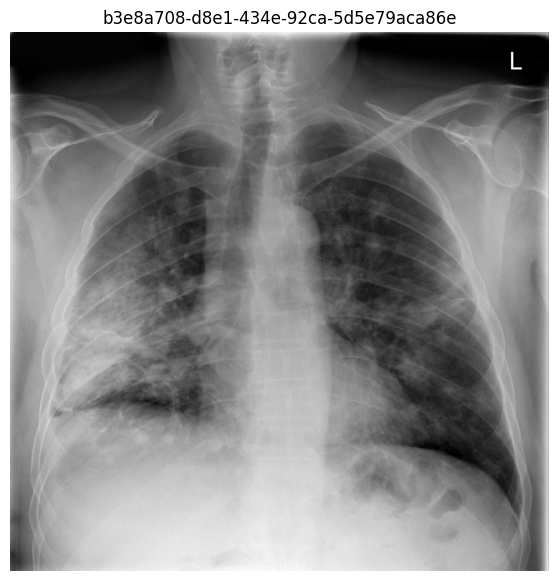

In [55]:
import random
import matplotlib.pyplot as plt

sample_path = random.choice(dicom_files)
sample_image = load_dicom_image(sample_path)

patient_id = sample_path.stem

patient_labels = labels[labels["patientId"] == patient_id]
patient_class = class_info[class_info["patientId"] == patient_id]

print("Patient ID:", patient_id)

print("\nClass information:")
display(patient_class)

print("\nAnnotation / bounding-box information:")
display(patient_labels)

plt.figure(figsize=(7, 7))
plt.imshow(sample_image, cmap="gray")
plt.title(patient_id)
plt.axis("off")
plt.show()

## 12. Preview Normal, abnormal-without-opacity, and Lung Opacity examples

This gives a useful first visual check of the three classes you may later use for a UniMed-CLIP experiment.

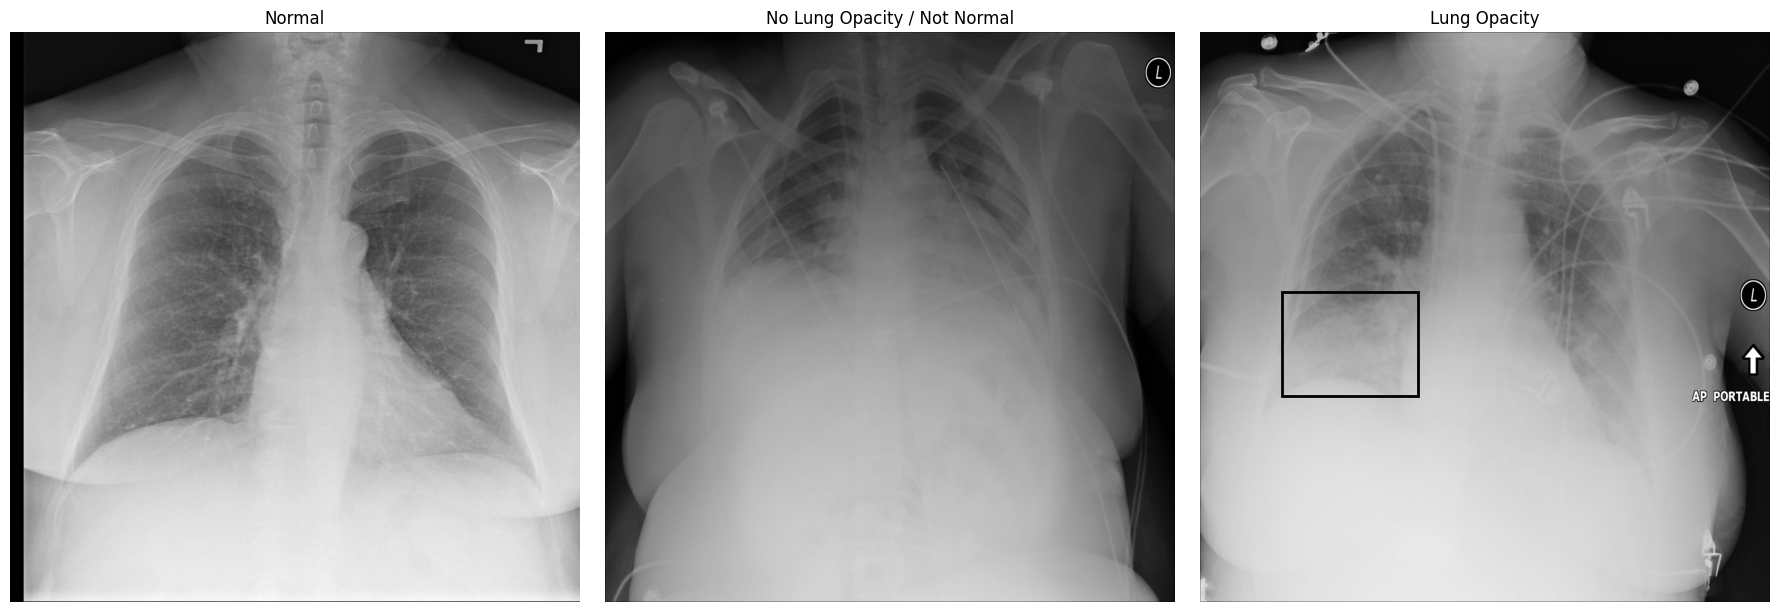

In [56]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import random

classes_to_show = [
    "Normal",
    "No Lung Opacity / Not Normal",
    "Lung Opacity"
]

# Get patient IDs from the DICOM files you actually downloaded
downloaded_patient_ids = {
    path.stem for path in TRAIN_IMAGE_DIR.glob("*.dcm")
}

# Keep only annotation rows for downloaded patients
available_patients = class_per_patient[
    class_per_patient["patientId"].isin(downloaded_patient_ids)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, class_name in zip(axes, classes_to_show):

    # Find downloaded patients belonging to this class
    candidates = available_patients[
        available_patients["class"] == class_name
    ]

    # Pick one random downloaded patient
    patient_id = candidates.sample(n=1)["patientId"].iloc[0]

    image_path = TRAIN_IMAGE_DIR / f"{patient_id}.dcm"
    image = load_dicom_image(image_path)

    ax.imshow(image, cmap="gray")
    ax.set_title(class_name)
    ax.axis("off")

    # Get pneumonia bounding boxes, if present
    patient_boxes = labels[
        (labels["patientId"] == patient_id) &
        (labels["Target"] == 1)
    ]

    for _, row in patient_boxes.iterrows():
        rect = Rectangle(
            (row["x"], row["y"]),
            row["width"],
            row["height"],
            fill=False,
            linewidth=2
        )

        ax.add_patch(rect)

plt.tight_layout()
plt.show()

## 13. Build a patient-level table for future CLIP analysis

The bounding-box file has multiple rows for some positive images. For classification, it is useful to create one row per image/patient.

In [ ]:
patient_targets = (
    labels.groupby("patientId", as_index=False)["Target"]
    .max()
)

patient_table = class_per_patient.merge(
    patient_targets,
    on="patientId",
    how="left"
)

patient_table["image_path"] = patient_table["patientId"].apply(
    lambda patient_id: str(TRAIN_IMAGE_DIR / f"{patient_id}.dcm")
)

print("Patient-level dataset shape:", patient_table.shape)
display(patient_table.head())


## 14. Optional: calculate opacity area for positive cases

This will be useful if the research project examines whether UniMed-CLIP performs differently for small versus large radiographic opacities.

In [ ]:
positive_boxes = labels[labels["Target"] == 1].copy()
positive_boxes["box_area"] = positive_boxes["width"] * positive_boxes["height"]

# Sum the annotated box areas for each image.
# This is a simple proxy and can double-count overlap between boxes.
opacity_area = (
    positive_boxes.groupby("patientId", as_index=False)["box_area"]
    .sum()
    .rename(columns={"box_area": "total_box_area"})
)

display(opacity_area.head())


## Next step

Once the dataset is downloaded and the previews work, the next notebook section can:

1. load the pretrained **UniMed-CLIP** model,
2. convert the DICOM images into the model's expected image format,
3. define pneumonia and normal text prompts,
4. calculate zero-shot similarity scores,
5. evaluate AUROC, sensitivity, specificity, accuracy, and F1,
6. test prompt sensitivity and performance by opacity extent.
